In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("cleaned_enriched.csv")
df = df.drop(columns=["socket", "turbo_clock_ghz"])
df = df.drop(index=5053)
df = df.drop(index=4387)

df["first_seen_year"] = pd.to_numeric(
    df["first_seen_year"], errors="coerce"
)

print("Строк без года:", df["first_seen_year"].isna().sum())
print(df.loc[df["first_seen_year"].isna(), ["name", "first_seen_year"]])

df = df.dropna(subset=["first_seen_year"]).copy()

features_with_nan = ["tdp_w", "l2_cache_mb", "l3_cache_mb"]
group_cols = ["manufacturer", "threads", "first_seen_year"]

has_group_keys = df[group_cols].notna().all(axis=1)

for column in features_with_nan:
    df[f"{column}_was_missing"] = df[column].isna().astype(int)

    group_median = (
        df.loc[has_group_keys]
          .groupby(group_cols)[column]
          .transform("median")
    )

    df.loc[has_group_keys, column] = (
        df.loc[has_group_keys, column].fillna(group_median)
    )

df["years_ago"] = (2026 - df["first_seen_year"]).astype(int)
df = df.drop(columns=["first_seen_year", "name"])

df = df[(df['category'] == 'Laptop') | (df['category'] == 'Desktop')]

df = pd.get_dummies(
    df,
    columns=["manufacturer"],
    prefix="manufacturer",
    drop_first=True,
    dtype=int
)
cache_cols = ["l2_cache_mb", "l3_cache_mb"]

df[cache_cols] = df[cache_cols].fillna(0)

print(df[cache_cols].isna().sum())

Строк без года: 0
Empty DataFrame
Columns: [name, first_seen_year]
Index: []
l2_cache_mb    0
l3_cache_mb    0
dtype: int64


In [3]:
#df['l2_cache_mb_int'] = df['l2_cache_mb'].apply(lambda row: 0 if row else row)
#df['l3_cache_mb_int'] = df['l3_cache_mb'].apply(lambda row: 0 if row else row)

In [4]:
semi_null_features = []
for column in df.columns:
    fullness = 1 - sum(df[column].isna()) / len(df[column])
    print(f'{column}: {fullness}')
    if 0.4 <= fullness <= 0.8: semi_null_features.append(column)
display(f'semi-null-features: {semi_null_features}')
display(f'shape of dataset: {df.shape}')

category: 1.0
cores: 1.0
threads: 0.9277854195323246
base_clock_ghz: 0.9790233837689133
tdp_w: 0.9889958734525447
l2_cache_mb: 1.0
l3_cache_mb: 1.0
cpu_mark: 1.0
tdp_w_was_missing: 1.0
l2_cache_mb_was_missing: 1.0
l3_cache_mb_was_missing: 1.0
years_ago: 1.0
manufacturer_Apple: 1.0
manufacturer_Intel: 1.0
manufacturer_Other: 1.0
manufacturer_Qualcomm: 1.0


'semi-null-features: []'

'shape of dataset: (2908, 16)'

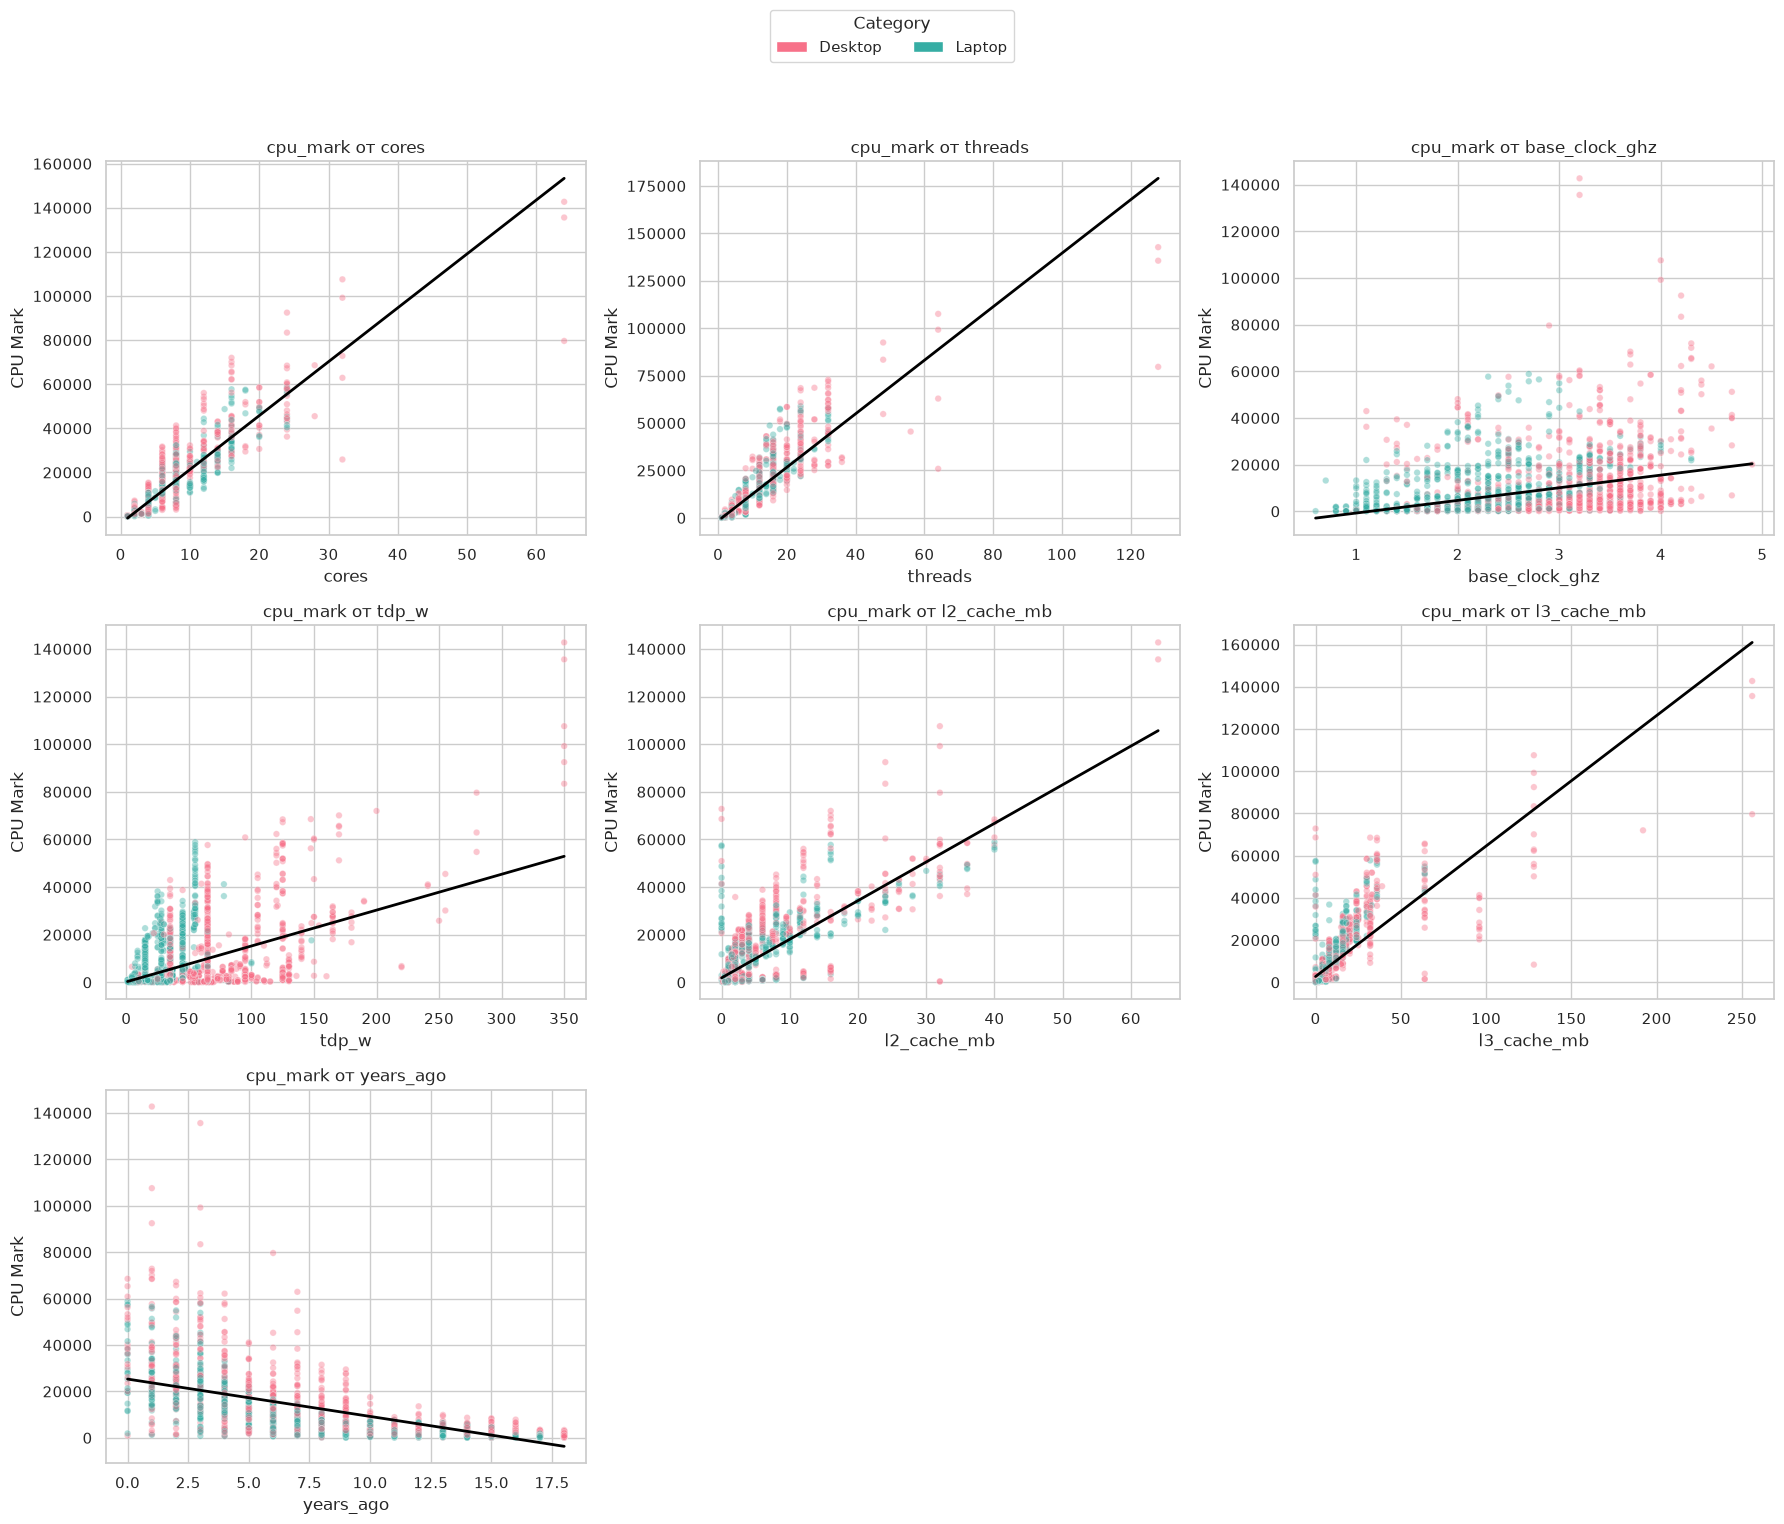

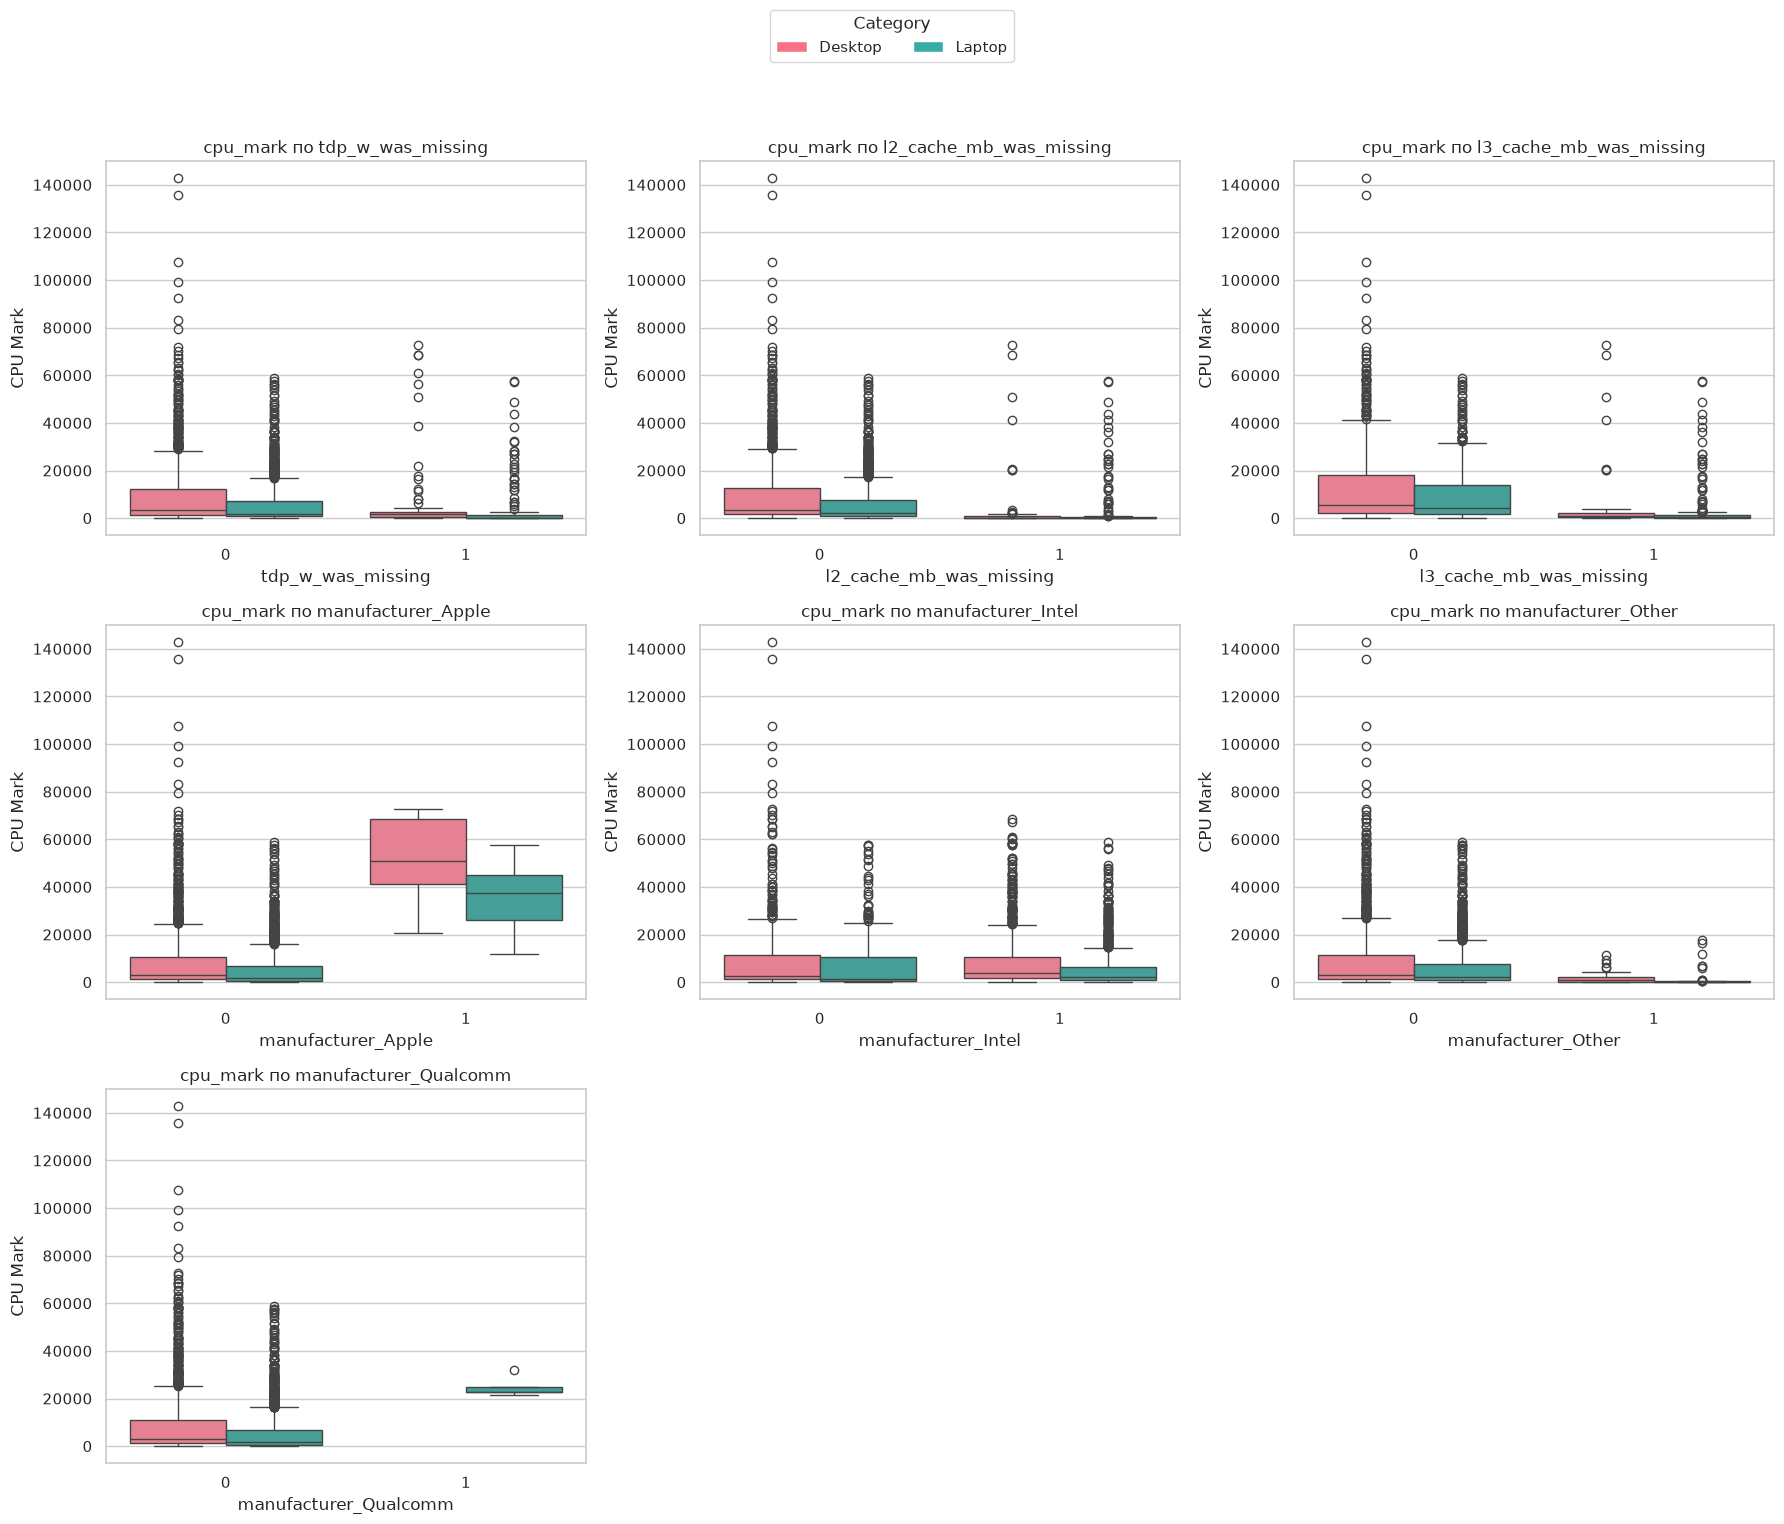

In [5]:
import math
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

sns.set_theme(style="whitegrid")

target = "cpu_mark"

plot_df = df.copy()
plot_df["category"] = (
    plot_df["category"]
    .astype("object")
    .fillna("Не указана")
    .astype(str)
)

categories = plot_df["category"].unique().tolist()
palette = dict(zip(
    categories,
    sns.color_palette("husl", n_colors=len(categories))
))

legend_items = [
    Patch(facecolor=palette[category], label=category)
    for category in categories
]

features = [
    column for column in plot_df.columns
    if column not in [target, "name", "category"]
]

categorical_features = plot_df[features].select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_features = [
    column for column in features
    if column not in categorical_features
]

binary_features = [
    column for column in numeric_features
    if plot_df[column].dropna().nunique() <= 2
]

continuous_features = [
    column for column in numeric_features
    if column not in binary_features
]

n_cols = 3

if continuous_features:
    n_rows = math.ceil(len(continuous_features) / n_cols)

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(18, 5 * n_rows)
    )
    axes = np.array(axes).reshape(-1)

    for ax, feature in zip(axes, continuous_features):
        sns.scatterplot(
            data=plot_df,
            x=feature,
            y=target,
            hue="category",
            hue_order=categories,
            palette=palette,
            alpha=0.4,
            s=22,
            legend=False,
            ax=ax
        )

        sns.regplot(
            data=plot_df,
            x=feature,
            y=target,
            scatter=False,
            ci=None,
            line_kws={"color": "black", "linewidth": 2},
            ax=ax
        )

        ax.set_title(f"{target} от {feature}")
        ax.set_ylabel("CPU Mark")

    for ax in axes[len(continuous_features):]:
        ax.remove()

    fig.legend(
        handles=legend_items,
        title="Category",
        loc="upper center",
        bbox_to_anchor=(0.5, 1.02),
        ncol=min(5, len(categories))
    )

    plt.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()


if binary_features:
    n_rows = math.ceil(len(binary_features) / n_cols)

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(18, 5 * n_rows)
    )
    axes = np.array(axes).reshape(-1)

    for ax, feature in zip(axes, binary_features):
        sns.boxplot(
            data=plot_df,
            x=feature,
            y=target,
            hue="category",
            hue_order=categories,
            palette=palette,
            dodge=True,
            ax=ax
        )

        if ax.get_legend() is not None:
            ax.get_legend().remove()

        ax.set_title(f"{target} по {feature}")
        ax.set_xlabel(feature)
        ax.set_ylabel("CPU Mark")

    for ax in axes[len(binary_features):]:
        ax.remove()

    fig.legend(
        handles=legend_items,
        title="Category",
        loc="upper center",
        bbox_to_anchor=(0.5, 1.02),
        ncol=min(5, len(categories))
    )

    plt.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()

In [6]:
df['category'].value_counts()

category
Laptop     1462
Desktop    1446
Name: count, dtype: int64

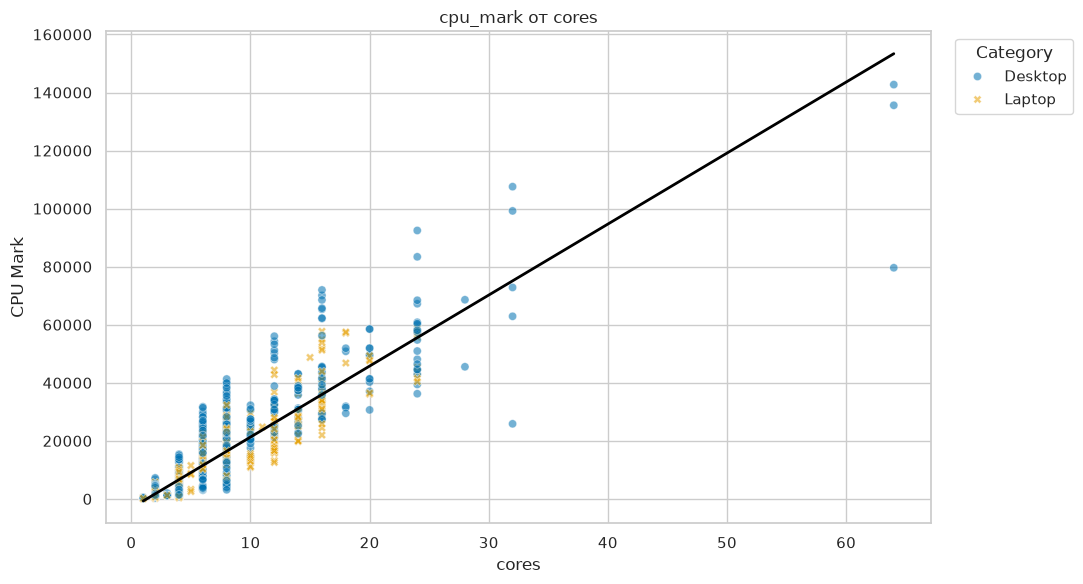

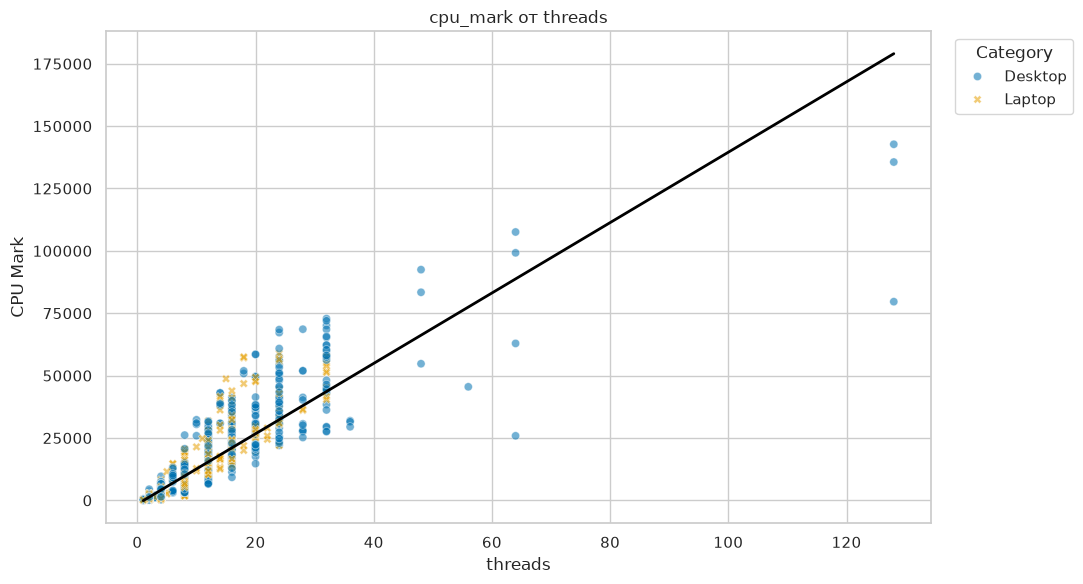

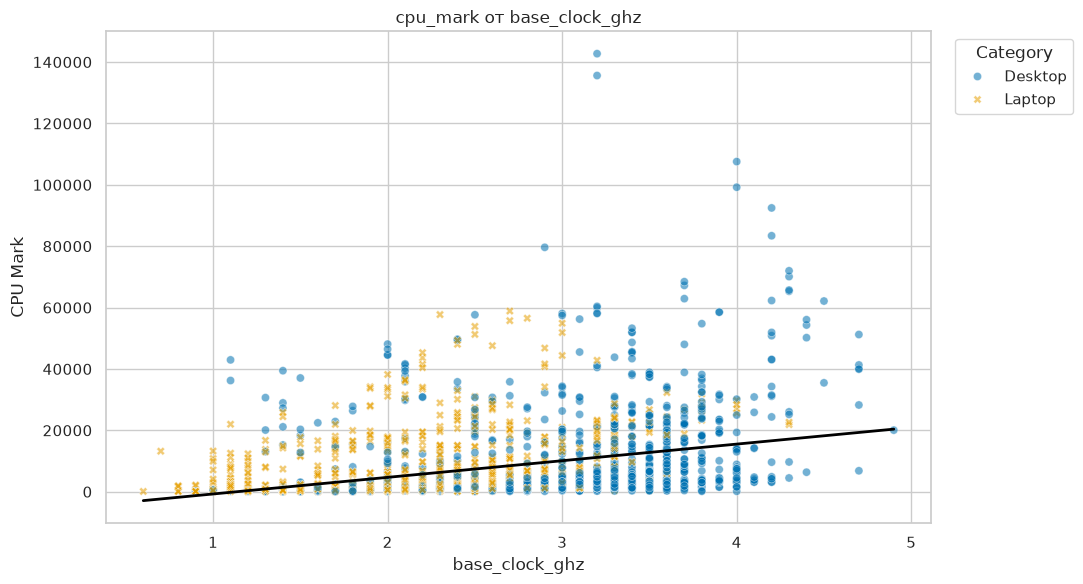

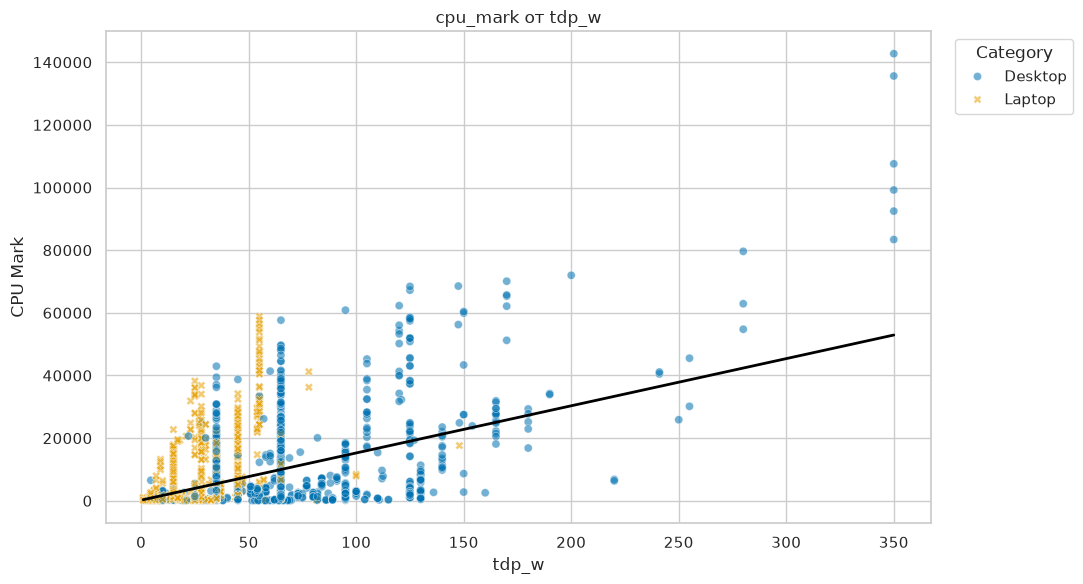

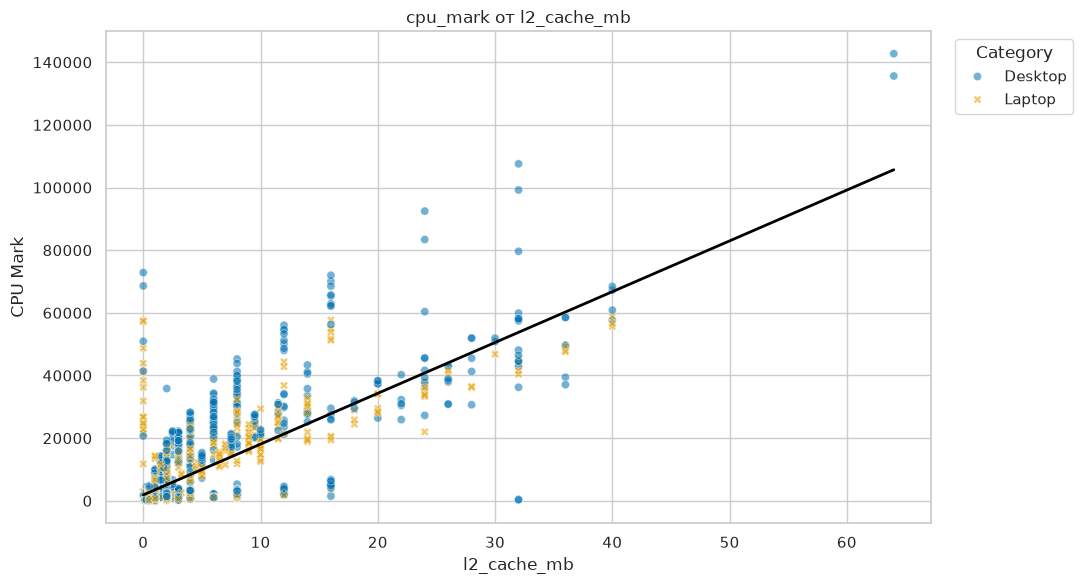

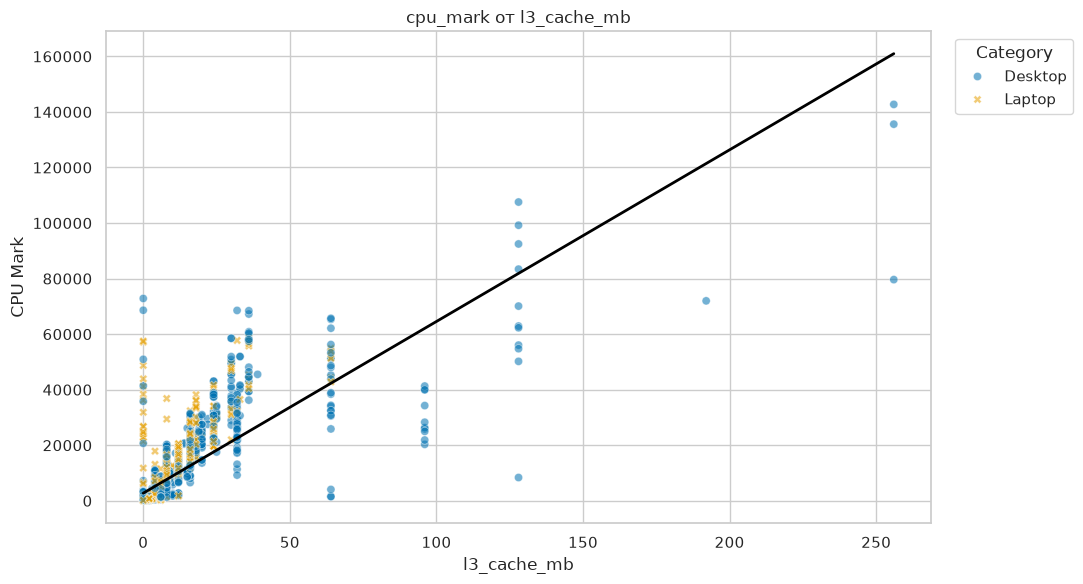

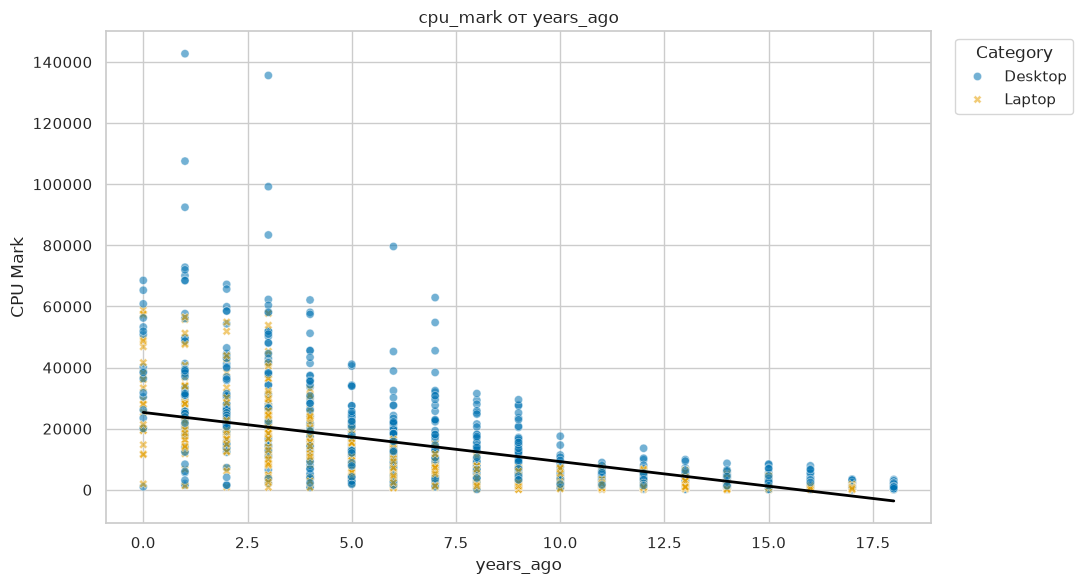

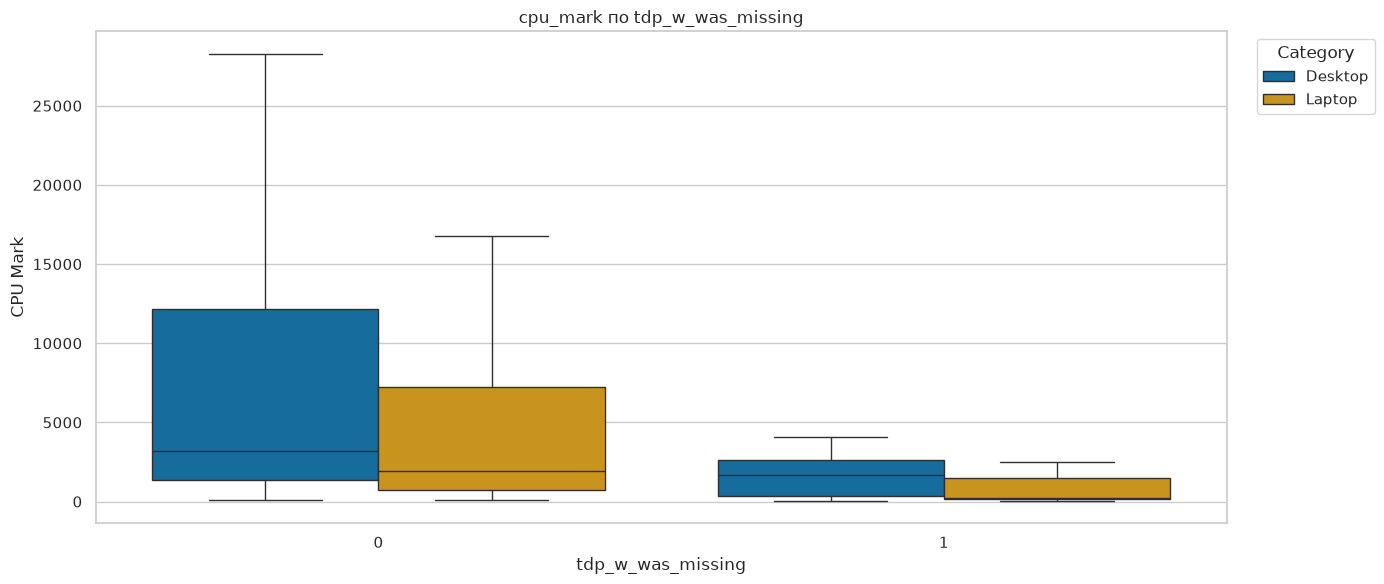

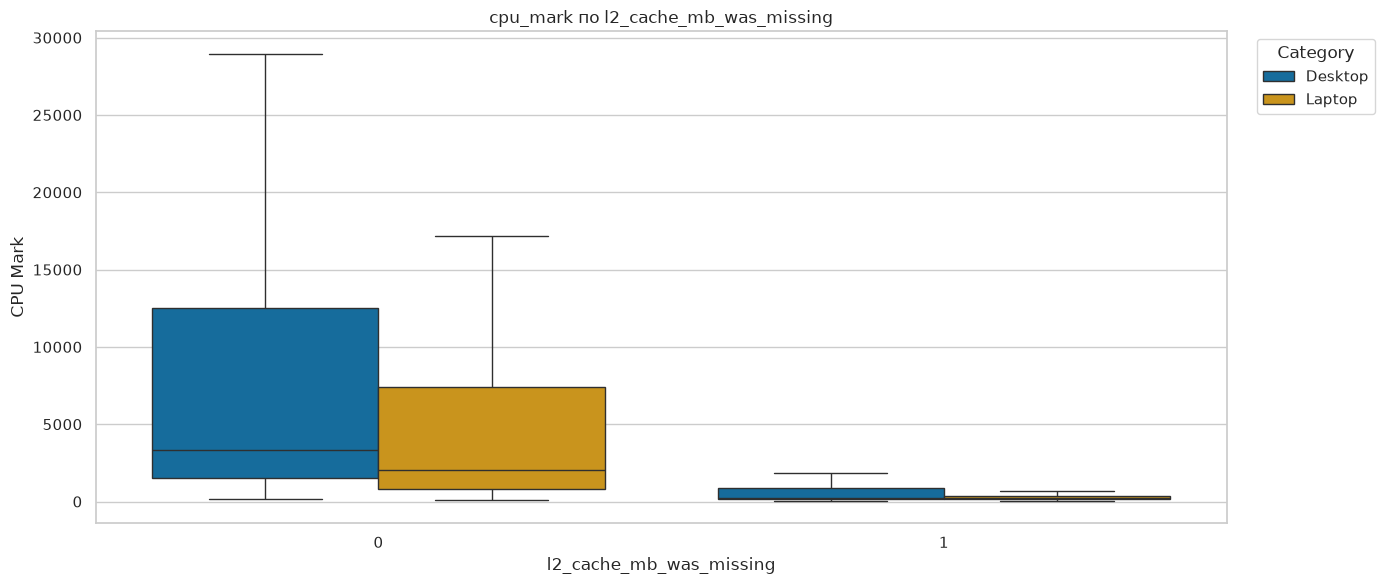

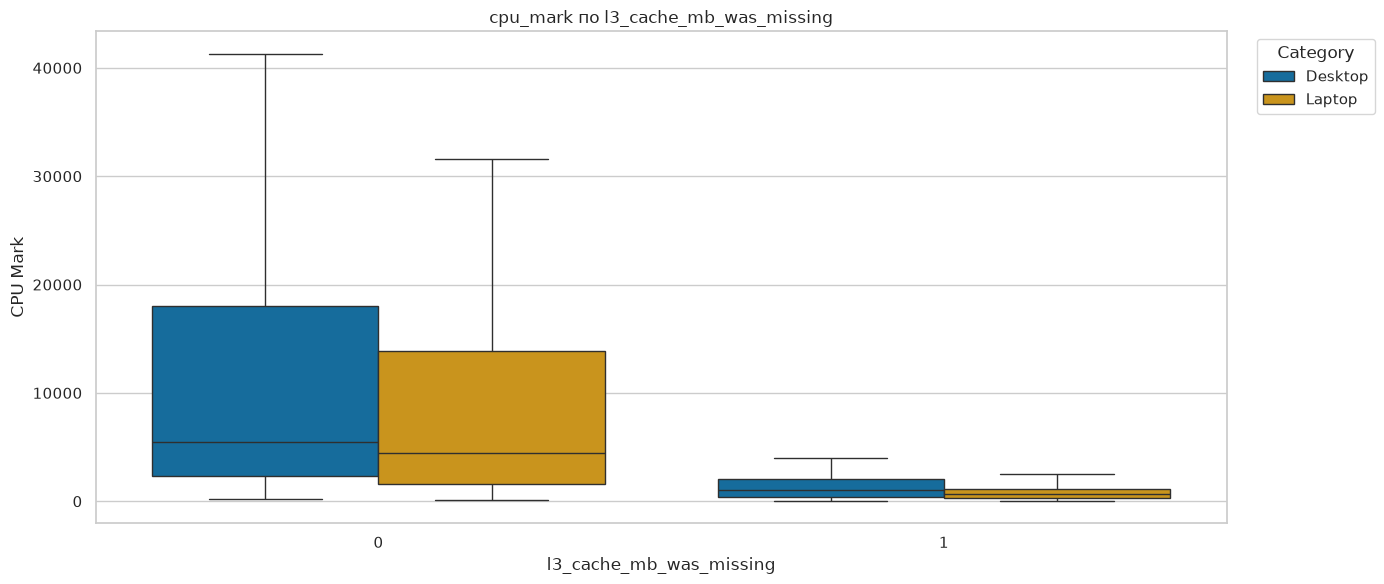

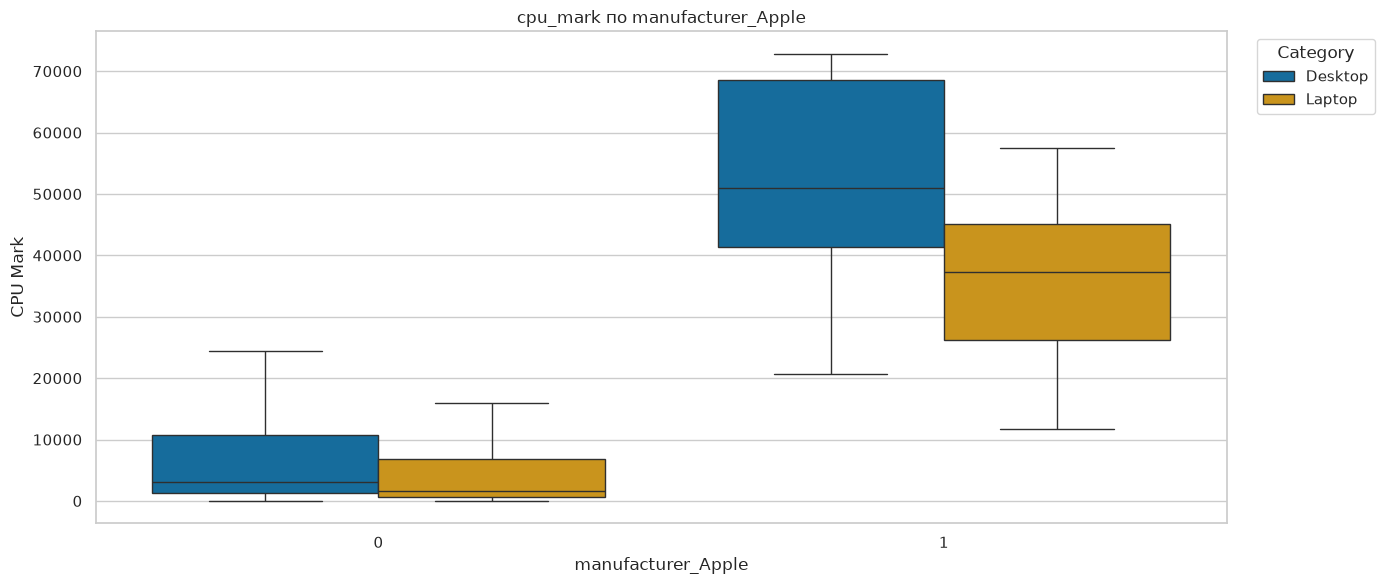

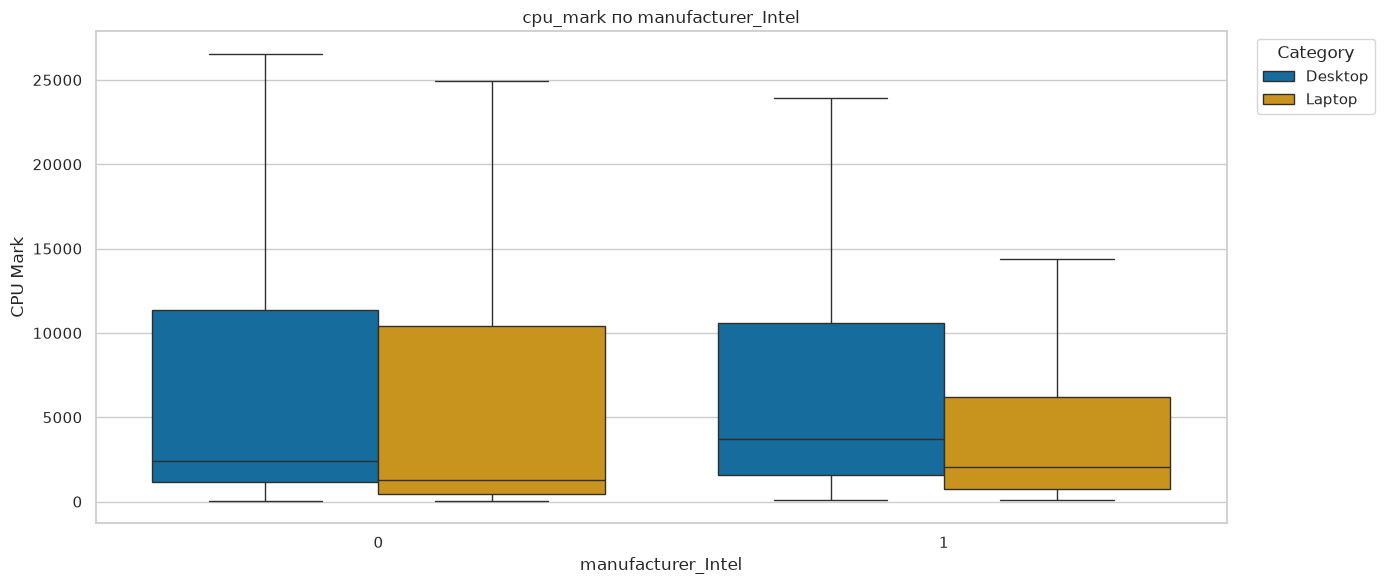

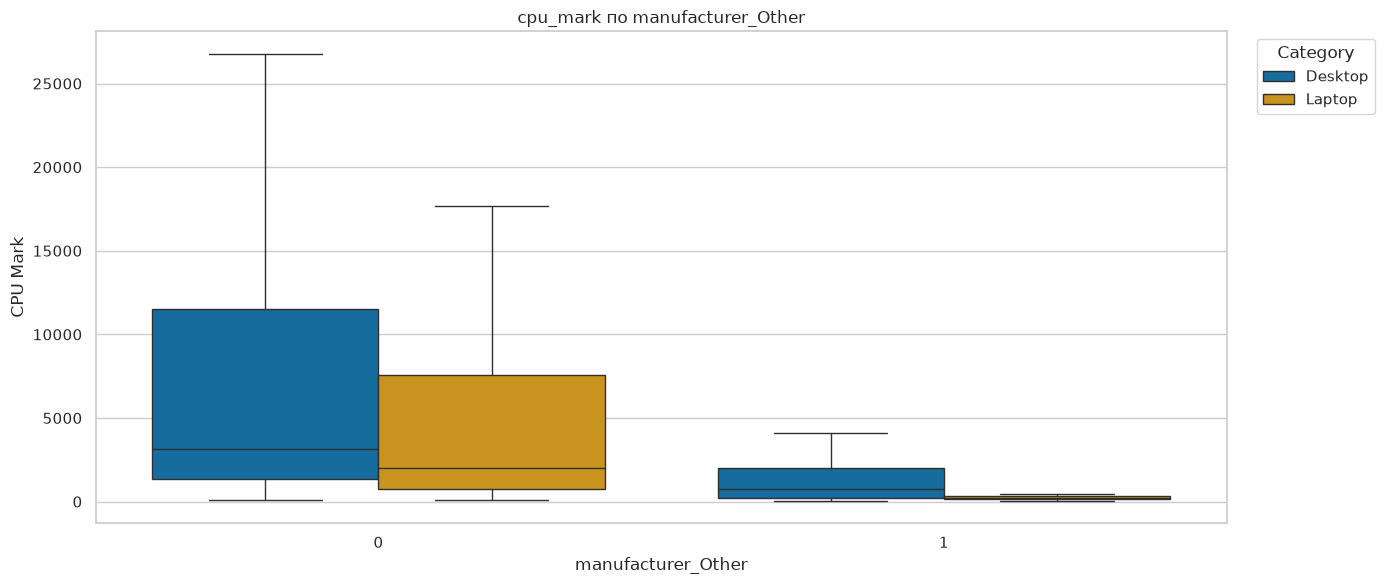

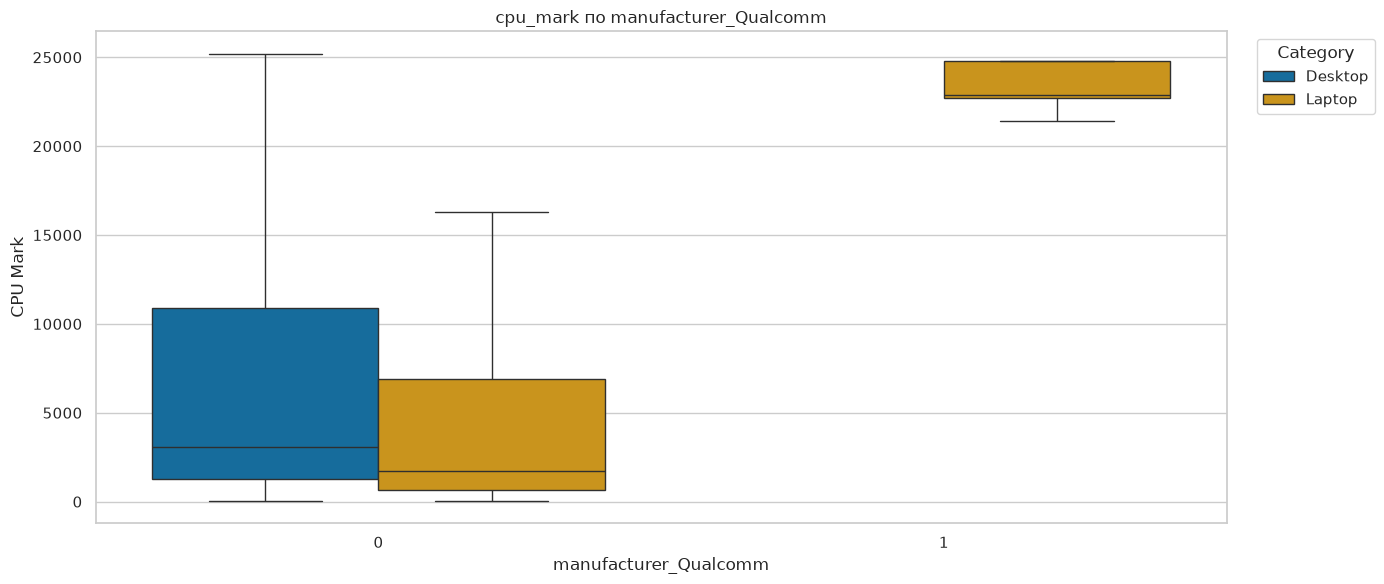

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

target = "cpu_mark"
plot_df = df.copy()

plot_df["category"] = (
    plot_df["category"]
    .astype("object")
    .fillna("Не указана")
    .astype(str)
)

categories = plot_df["category"].unique().tolist()

# Контрастные цвета для основных категорий.
palette = {
    "Desktop": "#0072B2",         
    "Laptop": "#E69F00",           
    "Server": "#009E73",           
    "Mobile/Embedded": "#D55E00",  
    "Не указана": "#555555",       
}

# Цвета для составных и других категорий.
extra_categories = [c for c in categories if c not in palette]
extra_colors = sns.color_palette("husl", n_colors=len(extra_categories))
palette.update(dict(zip(extra_categories, extra_colors)))

features = [
    column for column in plot_df.columns
    if column not in [target, "name", "category"]
    and not column.startswith("Unnamed:")
]

categorical_features = plot_df[features].select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_features = [
    column for column in features
    if column not in categorical_features
]

binary_features = [
    column for column in numeric_features
    if plot_df[column].dropna().nunique() <= 2
]

continuous_features = [
    column for column in numeric_features
    if column not in binary_features
]


for feature in continuous_features:
    fig, ax = plt.subplots(figsize=(11, 6))

    sns.scatterplot(
        data=plot_df,
        x=feature,
        y=target,
        hue="category",
        style="category",
        hue_order=categories,
        palette=palette,
        alpha=0.55,
        s=35,
        ax=ax
    )

    sns.regplot(
        data=plot_df,
        x=feature,
        y=target,
        scatter=False,
        ci=None,
        line_kws={"color": "black", "linewidth": 2},
        ax=ax
    )

    ax.set_title(f"{target} от {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("CPU Mark")

    ax.legend(
        title="Category",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()


for feature in binary_features:
    fig, ax = plt.subplots(figsize=(14, 6))

    sns.boxplot(
        data=plot_df,
        x=feature,
        y=target,
        hue="category",
        hue_order=categories,
        palette=palette,
        dodge=True,
        showfliers=False,
        ax=ax
    )

    ax.set_title(f"{target} по {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("CPU Mark")

    ax.legend(
        title="Category",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()

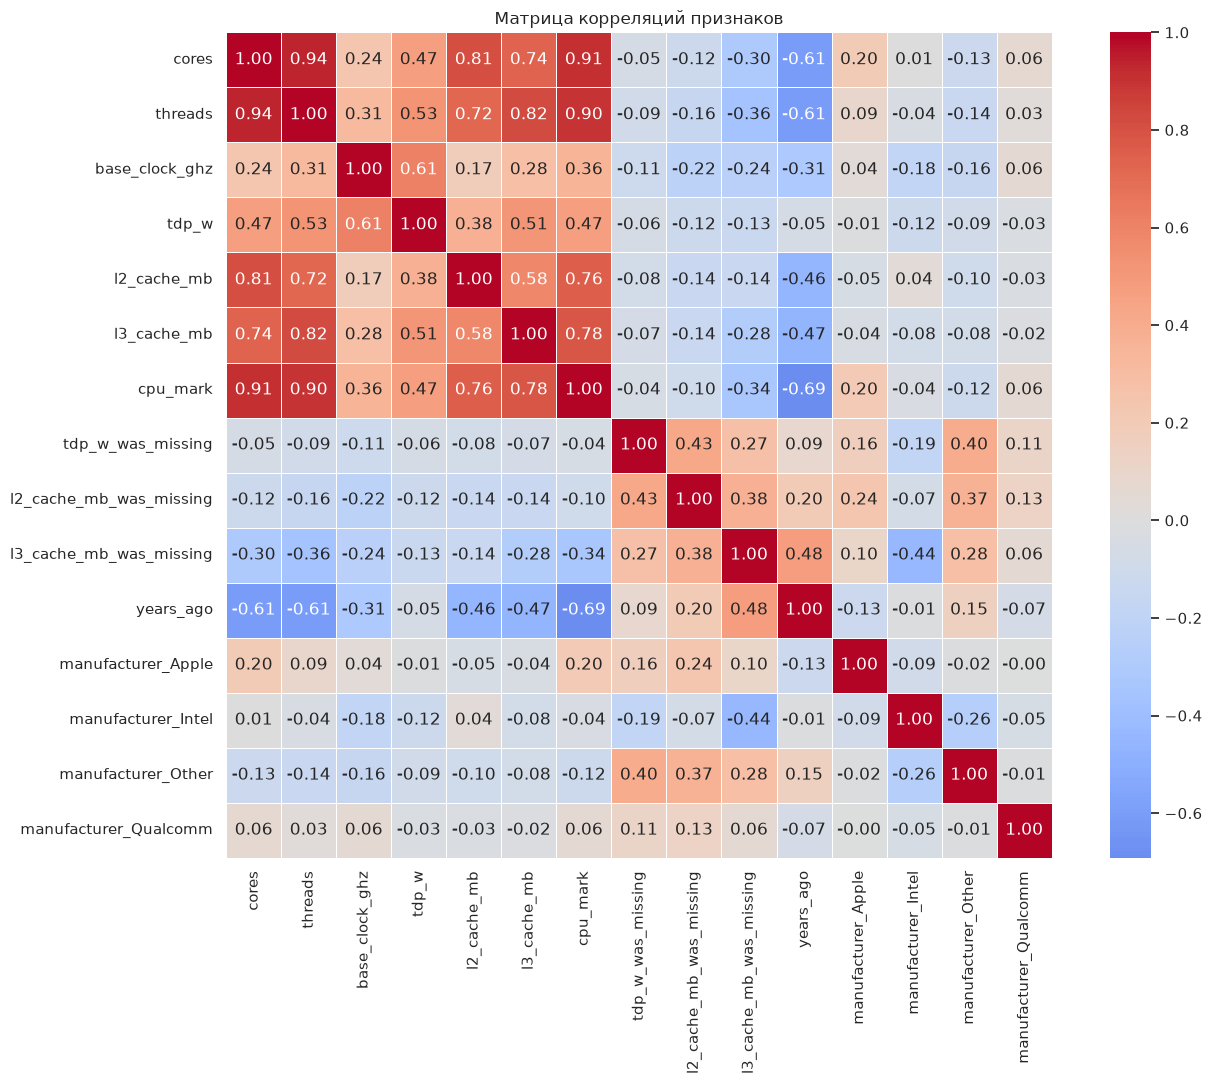

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_df = df.select_dtypes(include="number")

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(14, 11))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    square=True
)

plt.title("Матрица корреляций признаков")
plt.tight_layout()
plt.show()

In [9]:
missing_flags = [
    "tdp_w_was_missing",
    "l2_cache_mb_was_missing",
    "l3_cache_mb_was_missing"
]

df["specs_missing_count"] = df[missing_flags].sum(axis=1)

df = df.drop(columns=missing_flags)

In [10]:
df.to_csv('final3.csv')

In [11]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    MinMaxScaler,
    RobustScaler,
    StandardScaler,
)

data = df.copy()
data = data.loc[data["category"].isin(["Laptop", "Desktop"])].copy()
data["is_laptop"] = data["category"].eq("Laptop").astype(int)
data = data.drop(columns=["category", "Unnamed: 0"], errors="ignore")
data = data.dropna().copy()

X = data.drop(columns="cpu_mark")
y = data["cpu_mark"]

log_columns = [
    "cores", "threads", "tdp_w",
    "l2_cache_mb", "l3_cache_mb", "cores_x_clock",
]
other_numeric = [
    "base_clock_ghz", "years_ago", "specs_missing_count",
]
binary_columns = [
    col for col in X.columns if col.startswith("manufacturer_")
] + ["is_laptop"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

preprocessors = {
    "standard": ColumnTransformer([
        ("numeric", StandardScaler(), log_columns + other_numeric),
        ("binary", "passthrough", binary_columns),
    ]),
    "robust": ColumnTransformer([
        ("numeric", RobustScaler(), log_columns + other_numeric),
        ("binary", "passthrough", binary_columns),
    ]),
    "minmax": ColumnTransformer([
        ("numeric", MinMaxScaler(), log_columns + other_numeric),
        ("binary", "passthrough", binary_columns),
    ]),
    "log1p_standard": ColumnTransformer([
        ("log_numeric", Pipeline([
            ("log1p", FunctionTransformer(np.log1p)),
            ("scale", StandardScaler()),
        ]), log_columns),
        ("other_numeric", StandardScaler(), other_numeric),
        ("binary", "passthrough", binary_columns),
    ]),
}

results = []
fitted_searches = {}

for method, preprocessing in preprocessors.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessing),
        ("model", Ridge()),
    ])

    search = GridSearchCV(
        pipeline,
        param_grid={"model__alpha": np.logspace(-3, 4, 12)},
        scoring="neg_mean_absolute_error",
        cv=cv,
        n_jobs=-1,
    )
    search.fit(X_train, y_train)

    fitted_searches[method] = search
    results.append({
        "method": method,
        "cv_mae": -search.best_score_,
        "best_alpha": search.best_params_["model__alpha"],
    })

results = pd.DataFrame(results).sort_values("cv_mae")
display(results)

best_method = results.iloc[0]["method"]
best_model = fitted_searches[best_method].best_estimator_
pred = best_model.predict(X_test)

print("Строк после удаления пропусков:", len(data))
print("Выбранный метод:", best_method)
print("Test MAE:", mean_absolute_error(y_test, pred))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
print("Test R²:", r2_score(y_test, pred))

ValueError: 
All the 60 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
60 fits failed with the following error:
Traceback (most recent call last):
  File "/home/monkofwst/conda-envs/jupyter/lib/python3.12/site-packages/sklearn/utils/_indexing.py", line 411, in _get_column_indices
    return [column_names.index(col) for col in selected_columns]
            ^^^^^^^^^^^^^^^^^^^^^^^
ValueError: 'cores_x_clock' is not in list

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "/home/monkofwst/conda-envs/jupyter/lib/python3.12/site-packages/sklearn/model_selection/_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/home/monkofwst/conda-envs/jupyter/lib/python3.12/site-packages/

In [15]:
semi_null_features = []
for column in df.columns:
    fullness = 1 - sum(df[column].isna()) / len(df[column])
    print(f'{column}: {fullness}')
    if 0.4 <= fullness <= 0.8: semi_null_features.append(column)
display(f'semi-null-features: {semi_null_features}')
display(f'shape of dataset: {df.shape}')

category: 1.0
cores: 1.0
threads: 1.0
base_clock_ghz: 1.0
tdp_w: 1.0
l2_cache_mb: 1.0
l3_cache_mb: 1.0
cpu_mark: 1.0
years_ago: 1.0
manufacturer_Apple: 1.0
manufacturer_Intel: 1.0
manufacturer_Other: 1.0
manufacturer_Qualcomm: 1.0
specs_missing_count: 1.0


'semi-null-features: []'

'shape of dataset: (2623, 14)'

In [14]:
df.dropna(inplace=True)

In [16]:
df.to_csv("final4.csv")

In [19]:
df = df[df['category'] == 'Desktop']

In [20]:
df.to_csv('final4_desktop.csv')

In [21]:
df.shape

(1282, 14)

In [24]:
laptop = pd.read_csv('final4.csv')
laptop = laptop[laptop['category'] == 'Laptop']
laptop.to_csv('final4_laptop.csv')

In [25]:
laptop

,Unnamed: 0,category,cores,threads,base_clock_ghz,tdp_w,l2_cache_mb,l3_cache_mb,cpu_mark,years_ago,manufacturer_Apple,manufacturer_Intel,manufacturer_Other,manufacturer_Qualcomm,specs_missing_count
2,9,Laptop,4,8.0,2.4,47.0,1.000,6.0,5566,13,0,1,0,0,0
3,12,Laptop,2,2.0,2.0,31.0,1.000,2.0,645,17,0,0,0,0,1
4,13,Laptop,1,1.0,1.2,9.0,0.125,0.0,112,15,0,0,1,0,2
5,14,Laptop,2,2.0,1.3,10.0,3.000,1.0,536,17,0,1,0,0,1
6,16,Laptop,1,1.0,0.8,28.6,1.000,0.5,67,17,0,1,0,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2612,5971,Laptop,6,12.0,3.2,65.0,1.500,12.0,11738,7,0,1,0,0,0
2613,5976,Laptop,2,2.0,2.3,35.0,1.000,2.0,855,17,0,0,0,0,1
2616,5985,Laptop,2,2.0,2.2,35.0,1.000,2.0,641,17,0,0,0,0,1
2619,5995,Laptop,4,4.0,1.3,4.4,2.000,2.0,772,12,0,1,0,0,0


<Axes: xlabel='l3_cache_mb', ylabel='threads'>

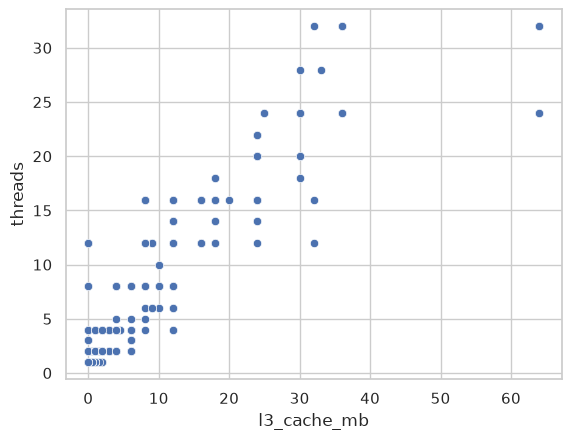

In [26]:
sns.scatterplot(data=laptop, x='l3_cache_mb', y='threads')